<div style="text-align: center; font-size: 32px">
Aula 04 - O Qiskit (Quantum Information Science Kit)
</div>

O Qiskit é um kit de desenvolvimento de software, criado originalmente pela IBM, com início em em 2017, para construir, simular e executar programas de computação quântica usando Python. Com ele, você pode:

- criar circuitos quânticos;
- aplicar portas como Hadamard, CNOT, \(R_x\) e \(R_z\);
- simular circuitos em um computador convencional;
- executar circuitos em computadores quânticos;
- analisar medições e visualizar resultados;
- implementar algoritmos completos.

  O objetico dessa aula é deixar você familiarizado com o ambiente de desenvolvimento e adquirir uma coleção de pequenos códigos com funcionalidades que serão utilizadas nos algoritmos.

## 01 - Imports
Abaixo está uma série de imports que você deverá usar ao desenvolver e analisar os algoritmos de computação quântica. 


In [10]:
from math import pi, gcd #(util para o algoritmo de Shor)

#apemas para operacoes e representacoes matemáticas
from fractions import Fraction
import numpy as np

#qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.visualization import plot_histogram
from qiskit.quantum_info import Statevector
from qiskit.visualization import array_to_latex

try:
    from qiskit_aer import AerSimulator
    backend = AerSimulator()
    print(":-)")
except Exception:
    backend = None
    print(":-(")

print("Importações carregadas!")

:-)
Importações carregadas!


## 02 - Inicialização de um circuito quântico
Aqui você irá definir quais qubits começão em o e quais em 1. Essas definicões dependem do algoritmo que está sendo implementado.

In [11]:
#TODO: inicie um circuito quantico com 4 qubits
n=4
qc=QuantumCircuit(n, n)

       
#TODO: #inicie os qubits 0 e 1 em zero. Inicie os qubits 2 e 3 em 1. 
qc.x(2)
qc.x(3)
#TODO gere uma barreira
qc.barrier()

print("Inicializado")
                

Inicializado


## 03 - Desenvolvimento do algoritmo
Sequencialmente, você pode aplicar portas quânticas aos qubits. 

In [12]:
#TODO: 
#- hadamard no qubit 0
qc.h(0)
#- inversao controlada. qubit controle: 0. Qubit alvo: 1
qc.cx(0, 1)
#- inversao controlada. qubit controle: 3. Qubit alvo: 2
qc.cx(3, 2)
#- rotacao em x de 30 graus controlada. qubit controle: 3. Qubit alvo: 2
qc.crx(pi/6, 3, 2)
#- rotacao em z de 30 graus no qubit 2
qc.rz(pi/6, 2)


#TODO gere uma barreira
print("Parte 01 implementada")

Parte 01 implementada


## 04 - Visualização do circuito

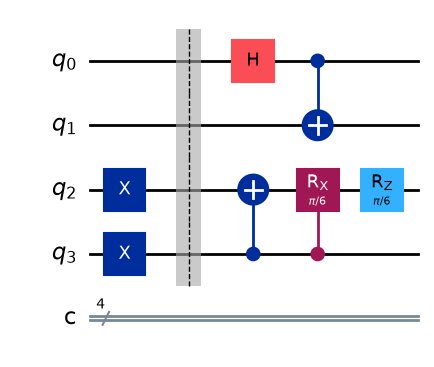

In [13]:
#TODO: visualize seu circuito
qc.draw('mpl')

## 05 - Analisando estados. 
Vamos agora analisar o vetor estado do circuito na segunda barreira. 

In [14]:
#TODO gere o vetor de estados 
sv = Statevector.from_instruction(qc)

sv_coluna = np.array(sv).reshape(-1, 1)

display(array_to_latex(sv_coluna, precision=2, max_size=100))

<IPython.core.display.Latex object>

## 06 - Separando módulos e fases
Aqui você irá observar os módulos dos estados, que dão a raiz das probabilidades. E também as fases, separadamente

In [15]:
#TODO extraia os modulos e as fases dos estados
display(array_to_latex(np.abs(sv_coluna), precision=2, max_size=100))
display(array_to_latex(np.angle(sv_coluna), precision=2, max_size=100))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

## 07 - Execução no simulador e medição
Aqui vamos simular a execução do circuito em um computador quântico e medir a saída. Faremos milhares de execuções, cada uma resultando numa medida que seguem as probabilidades dos estados (raíz quadrada dos módulos). Repare que só há possibilidades de 4 saidas.




{'1111': 314, '1011': 4697, '1100': 333, '1000': 4656}


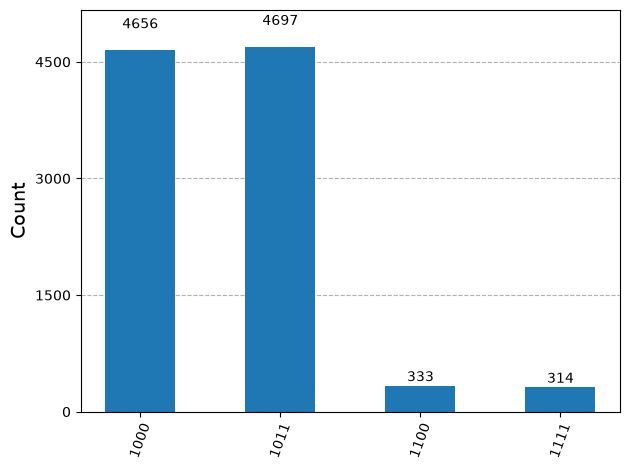

In [16]:
#TODO: Calcule as probabilidades dos estados, mostre quais sao eles.
#TODO: Simule mais de 2 mil vezes o circuito e analise se as ocorrencias seguem as probabilidades ditas pelas raizes dos modulos 
counts = None
qc.measure(range(n), range(n))

if backend is not None:
    tqc = transpile(qc, backend)

    result = backend.run(tqc, shots=10000).result()

    counts = result.get_counts(tqc)
    print(counts)
    try:
        display(plot_histogram(counts))
    except Exception:
        pass
else:
    print("qiskit_aet não está disponível neste ambiente.")



## 08 - Print do circuito completo, com a medição
Veja como seria a representação da medição final!

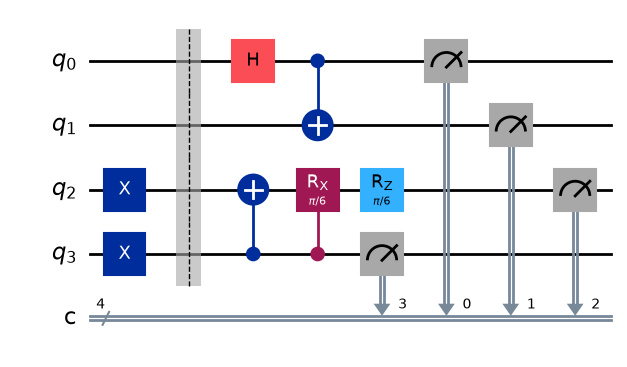

In [17]:
#TODO ptint do circuito
qc.draw('mpl')